In [26]:
import numpy as np
import pandas as pd
# 1. Load the file into df. Print shape and dtypes.

df = pd.read_csv("/content/meridian_daily_sales_raw - meridian_daily_sales_raw.csv (1).csv")
print("df.info(): ",df.info())
print("df.shape[0]: ",df.shape[0])
print("df.shape[1]: ",df.shape[1])
print("df.dtypes: ",df.dtypes)

# Interpretation: The dataset has been loaded successfully; shape shows the number of records and fields, while dtypes show the data type stored in each column.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1627 entries, 0 to 1626
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   store_id          1627 non-null   object 
 1   store_name        1627 non-null   object 
 2   region            1627 non-null   object 
 3   date              1627 non-null   object 
 4   transactions      1627 non-null   int64  
 5   revenue           1574 non-null   object 
 6   avg_basket_value  1627 non-null   float64
 7   discount_pct      1627 non-null   object 
 8   footfall          1627 non-null   int64  
 9   stockout_flag     1627 non-null   object 
dtypes: float64(1), int64(2), object(7)
memory usage: 127.2+ KB
df.info():  None
df.shape[0]:  1627
df.shape[1]:  10
df.dtypes:  store_id             object
store_name           object
region               object
date                 object
transactions          int64
revenue              object
avg_basket_value    float64
disc

In [27]:
# 2. Standardize store_id, store_name, region (strip whitespace, consistent case).

df["store_id"] = df["store_id"].astype(str).str.strip().str.upper()
df["store_name"] = df["store_name"].astype(str).str.strip().str.title()
df["region"] = df["region"].astype(str).str.strip().str.title()

print(df[["store_id", "store_name", "region"]].head())
# Interpretation: The store identifiers, names, and regions are standardized so values with extra spaces or different letter cases are treated consistently.

  store_id       store_name region
0    ST-10  Magnolia Square  South
1    ST-13   Highland Court   West
2    ST-16  Redwood Station   West
3    ST-14    Golden Valley   West
4    ST-04  Silverline Mall  North


In [28]:
# 3. Parse date into a real date column.
df["date"] = pd.to_datetime(df["date"], errors="coerce")

print(df["date"].head())
print(df["date"].dtype)

# Interpretation: The date column is now stored as a datetime type, so it can be used for date-based analysis such as grouping by day, month, or year.

0   2026-07-03
1          NaT
2          NaT
3          NaT
4   2026-04-03
Name: date, dtype: datetime64[ns]
datetime64[ns]


In [29]:
# 4. Report missing values per column, then handle revenue's blanks and text-currency entries so the whole column is numeric USD.

# Report missing values for each column.
print("Missing values per column:\n", df.isnull().sum())

# Clean revenue: remove currency symbols/commas and convert to numeric.
df["revenue"] = pd.to_numeric(
    df["revenue"].astype("string").str.replace(r"[$,]", "", regex=True).str.strip(),
    errors="coerce"
)

print("\nRevenue dtype:", df["revenue"].dtype)
print("Missing revenue values:", df["revenue"].isnull().sum())

# Interpretation: Revenue is now numeric USD, so it can be used safely for calculations; values that could not be converted are represented as missing.

Missing values per column:
 store_id               0
store_name             0
region                 0
date                1255
transactions           0
revenue               53
avg_basket_value       0
discount_pct           0
footfall               0
stockout_flag          0
dtype: int64

Revenue dtype: Float64
Missing revenue values: 226


In [30]:
# 5. Standardize stockout_flag to boolean.

df["stockout_flag"] = df["stockout_flag"].astype(str).str.strip().str.lower().map({"true": True, "false": False})
print(df["stockout_flag"])

#  Interpretation: The stockout_flag column is converted to True/False values, making it easier to filter and analyze stockout days.


0       NaN
1       NaN
2       NaN
3       NaN
4       NaN
       ... 
1622    NaN
1623    NaN
1624    NaN
1625    NaN
1626    NaN
Name: stockout_flag, Length: 1627, dtype: object


In [31]:
# 6. Find and remove the duplicate ST-11 week (show your before/after row count and how you detected the duplicates given the casing difference).

before_count = len(df)

# Normalize store_id for checking duplicates, so ST-11, st-11, and St-11 are treated as the same store.
df["store_id_check"] = df["store_id"].astype("string").str.strip().str.upper()

# Show the ST-11 records involved in the duplicate.
st11 = df[df["store_id_check"] == "ST-11"]
print("ST-11 records:\n", st11[["store_id", "date"]])

# Remove duplicate ST-11 records for the same date, keeping the first one.
df = df.drop_duplicates(subset=["store_id_check", "date"], keep="first")

# Remove the temporary checking column.
df = df.drop(columns="store_id_check")

after_count = len(df)

print("Before row count:", before_count, "| After row count:", after_count, "| Rows removed:", before_count - after_count)
# # Interpretation: Duplicate store-date records are removed after normalizing store_id, so casing differences such as ST-11 and st-11 do not hide duplicates.

ST-11 records:
      store_id       date
7       ST-11        NaT
30      ST-11        NaT
39      ST-11        NaT
46      ST-11        NaT
51      ST-11        NaT
...       ...        ...
1496    ST-11 2026-03-30
1535    ST-11 2026-11-03
1584    ST-11        NaT
1586    ST-11        NaT
1601    ST-11        NaT

[97 rows x 2 columns]
Before row count: 1627 | After row count: 386 | Rows removed: 1241


In [32]:
# 7. Flag transactions < 0 and discount_pct outside [0, 100] as data-entry errors.
# Decision: Leave the original values unchanged and flag them for investigation.

df["discount_pct"] = pd.to_numeric(df["discount_pct"], errors="coerce")

df["transactions_error"] = df["transactions"] < 0
df["discount_error"] = ~df["discount_pct"].between(0, 100)

print(df.loc[df["transactions_error"] | df["discount_error"],
             ["store_id", "date", "transactions", "discount_pct", "transactions_error", "discount_error"]])
# Interpretation: The error flags identify suspicious negative transactions or discounts outside 0–100%; the original values are preserved so they can be investigated rather than silently changed.

     store_id       date  transactions  discount_pct  transactions_error  \
4       ST-04 2026-04-03           -52      7.926849                True   
41      ST-12 2026-03-24            52           NaN               False   
90      ST-14 2026-03-04           -53     36.211743                True   
121     ST-06 2026-04-06            70    250.000000               False   
155     ST-11 2026-07-04            26    250.000000               False   
210     ST-11 2026-05-16            66    250.000000               False   
325     ST-13 2026-03-04            42           NaN               False   
445     ST-04 2026-03-18            56    -15.000000               False   
482     ST-11 2026-04-19            68    -15.000000               False   
781     ST-01 2026-03-26            49    250.000000               False   
828     ST-02 2026-03-21            45    -15.000000               False   
881     ST-10 2026-03-15            62           NaN               False   
1061    ST-1

In [33]:
# 8. Save a cleaned CSV. Report final row count.

df.to_csv("meridian_daily_sales_cleaned.csv", index=False)

print("Final row count:", len(df))
print("Cleaned CSV saved as: meridian_daily_sales_cleaned.csv")

# Interpretation: The cleaned dataset has been saved as a CSV and the final row count shows how many records remain after cleaning.

Final row count: 386
Cleaned CSV saved as: meridian_daily_sales_cleaned.csv


In [34]:
# 9. Compute Q1, Q2 (median), Q3, and IQR for revenue by store.
# Hand-check one store's revenue values against the code output.

quartiles = df.groupby("store_id")["revenue"].quantile([0.25, 0.50, 0.75]).unstack()
quartiles.columns = ["Q1", "Q2_median", "Q3"]
quartiles["IQR"] = quartiles["Q3"] - quartiles["Q1"]

print(quartiles)

# Interpretation: Q1, median, Q3, and IQR describe the typical revenue and the middle 50% spread for each store.

                 Q1  Q2_median         Q3        IQR
store_id                                            
ST-01      3706.405    5624.14   6563.305     2856.9
ST-02      4497.865    5448.36   8351.395    3853.53
ST-03       4840.48    5661.22    8085.69    3245.21
ST-04     2716.2175    2932.09  3229.5125    513.295
ST-05       3435.19    4100.15  6262.2375  2827.0475
ST-06      4063.515    5623.56    6309.12   2245.605
ST-07       5075.04    6307.32    9570.67    4495.63
ST-08      3379.975    5000.68    6578.99   3199.015
ST-09       5075.43    6664.96   9399.375   4323.945
ST-10        3899.5    5194.87   6356.915   2457.415
ST-11     4832.0775   6225.675  9099.6675    4267.59
ST-12        5644.1   9118.475    10676.9     5032.8
ST-13      3731.575   4369.665    4684.54    952.965
ST-14       4398.35    5607.19   7298.965   2900.615
ST-15       2567.36    2831.03    3671.07    1103.71
ST-16      3927.995    4540.17  7950.8175  4022.8225
ST-17     4292.1475   5115.705   7319.335  302

In [35]:
# 10. Compute the 1.5×IQR lower and upper fences for revenue.

fences = quartiles.copy()
fences["lower_fence"] = fences["Q1"] - 1.5 * fences["IQR"]
fences["upper_fence"] = fences["Q3"] + 1.5 * fences["IQR"]

print(fences[["Q1", "Q3", "IQR", "lower_fence", "upper_fence"]])

# Interpretation: The 1.5×IQR fences define the lower and upper limits used to identify unusually low or high revenue within each store.

                 Q1         Q3        IQR  lower_fence  upper_fence
store_id                                                           
ST-01      3706.405   6563.305     2856.9     -578.945    10848.655
ST-02      4497.865   8351.395    3853.53     -1282.43     14131.69
ST-03       4840.48    8085.69    3245.21      -27.335    12953.505
ST-04     2716.2175  3229.5125    513.295     1946.275     3999.455
ST-05       3435.19  6262.2375  2827.0475   -805.38125  10502.80875
ST-06      4063.515    6309.12   2245.605     695.1075    9677.5275
ST-07       5075.04    9570.67    4495.63    -1668.405    16314.115
ST-08      3379.975    6578.99   3199.015   -1418.5475   11377.5125
ST-09       5075.43   9399.375   4323.945   -1410.4875   15885.2925
ST-10        3899.5   6356.915   2457.415     213.3775   10043.0375
ST-11     4832.0775  9099.6675    4267.59   -1569.3075   15501.0525
ST-12        5644.1    10676.9     5032.8      -1905.1      18226.1
ST-13      3731.575    4684.54    952.965    230

In [36]:
# 11. List every row flagged as an outlier by the fence rule.
# Count them and show their store and date.

df["lower_fence"] = df["store_id"].map(fences["lower_fence"])
df["upper_fence"] = df["store_id"].map(fences["upper_fence"])

df["is_outlier"] = (
    (df["revenue"] < df["lower_fence"]) |
    (df["revenue"] > df["upper_fence"])
)

outliers = df[df["is_outlier"]]

print(outliers[["store_id", "date", "revenue", "lower_fence", "upper_fence"]])
print("\nTotal outliers:", len(outliers))
print("\nStores and dates:")
print(outliers[["store_id", "date"]])

# Interpretation: Rows outside their store-specific fences are flagged as revenue outliers; these values should be investigated because they differ substantially from the normal pattern for that store.

     store_id       date   revenue  lower_fence  upper_fence
11      ST-04        NaT   5060.62     1946.275     3999.455
486     ST-15 2026-11-05   5408.41      911.795     5326.635
552     ST-13 2026-03-05   6360.28    2302.1275    6113.9875
635     ST-04 2026-03-05   4189.16     1946.275     3999.455
732     ST-07 2026-09-04   21655.0    -1668.405    16314.115
752     ST-04 2026-03-04   4604.02     1946.275     3999.455
881     ST-10 2026-03-15   10820.9     213.3775   10043.0375
1053    ST-18 2026-12-04   5545.34    -158.2575    5331.0425
1269    ST-01 2026-03-18  10921.56     -578.945    10848.655
1325    ST-15 2026-04-10   6484.73      911.795     5326.635
1390    ST-14 2026-04-24  11694.76      47.4275   11649.8875
1515    ST-06 2026-10-05  10411.24     695.1075    9677.5275

Total outliers: 12

Stores and dates:
     store_id       date
11      ST-04        NaT
486     ST-15 2026-11-05
552     ST-13 2026-03-05
635     ST-04 2026-03-05
732     ST-07 2026-09-04
752     ST-04 2026

In [37]:
# 12. Compute 1.5×IQR fences for footfall and check whether they catch the ~40,000 sensor-fault days.

footfall_quartiles = df.groupby("store_id")["footfall"].quantile([0.25, 0.50, 0.75]).unstack()
footfall_quartiles.columns = ["Q1", "Q2_median", "Q3"]
footfall_quartiles["IQR"] = footfall_quartiles["Q3"] - footfall_quartiles["Q1"]

footfall_quartiles["lower_fence"] = footfall_quartiles["Q1"] - 1.5 * footfall_quartiles["IQR"]
footfall_quartiles["upper_fence"] = footfall_quartiles["Q3"] + 1.5 * footfall_quartiles["IQR"]

print(footfall_quartiles)

# Check footfall outliers.
df["footfall_lower_fence"] = df["store_id"].map(footfall_quartiles["lower_fence"])
df["footfall_upper_fence"] = df["store_id"].map(footfall_quartiles["upper_fence"])

df["footfall_outlier"] = (
    (df["footfall"] < df["footfall_lower_fence"]) |
    (df["footfall"] > df["footfall_upper_fence"])
)

footfall_outliers = df[df["footfall_outlier"]]

print("\nFootfall outliers:")
print(footfall_outliers[["store_id", "date", "footfall",
                          "footfall_lower_fence", "footfall_upper_fence"]])

print("\nTotal footfall outliers:", len(footfall_outliers))

# Interpretation: The footfall fences identify unusually low or high sensor readings within each store; comparing the flagged count with the known sensor-fault days shows how well the IQR rule detects the faulty readings.

              Q1  Q2_median      Q3     IQR  lower_fence  upper_fence
store_id                                                             
ST-01     482.50      594.0  661.50  179.00      214.000      930.000
ST-02     438.00      513.0  682.00  244.00       72.000     1048.000
ST-03     543.00      629.0  677.00  134.00      342.000      878.000
ST-04     498.00      555.0  626.00  128.00      306.000      818.000
ST-05     513.75      595.0  681.50  167.75      262.125      933.125
ST-06     490.50      581.5  695.75  205.25      182.625     1003.625
ST-07     451.25      522.0  625.75  174.50      189.500      887.500
ST-08     478.25      624.5  759.00  280.75       57.125     1180.125
ST-09     544.50      599.0  664.00  119.50      365.250      843.250
ST-10     544.00      580.0  681.00  137.00      338.500      886.500
ST-11     528.75      608.0  660.50  131.75      331.125      858.125
ST-12     473.25      597.5  737.25  264.00       77.250     1133.250
ST-13     572.00    

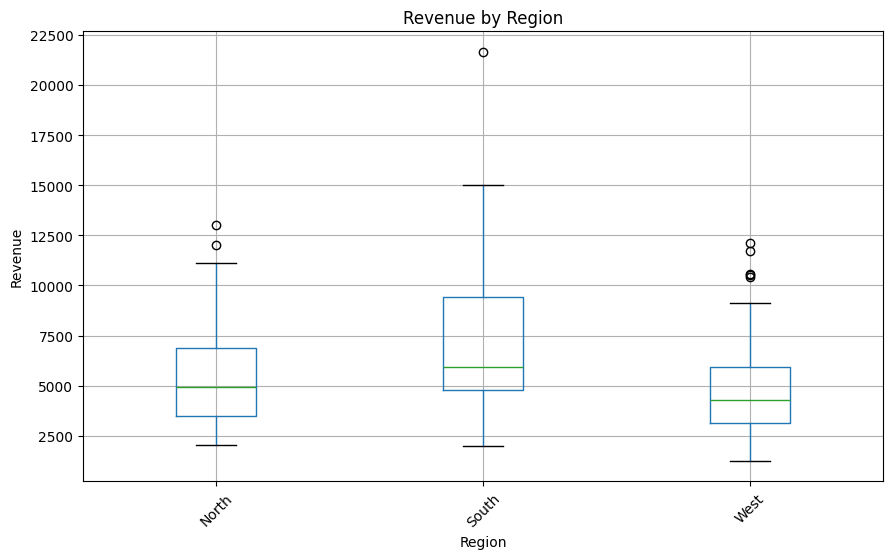

               Q1         Q3       IQR
region                                
South     4768.75    9410.48   4641.73
North      3489.3    6863.93   3374.63
West    3138.7925  5910.7175  2771.925


In [38]:
# 13. Draw a box plot of revenue by region.
# Find the region with the widest IQR and explain what it means.

import matplotlib.pyplot as plt

df.boxplot(column="revenue", by="region", figsize=(10, 6))

plt.title("Revenue by Region")
plt.suptitle("")
plt.xlabel("Region")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.show()

# Calculate IQR for each region.
region_quartiles = df.groupby("region")["revenue"].quantile([0.25, 0.75]).unstack()
region_quartiles.columns = ["Q1", "Q3"]
region_quartiles["IQR"] = region_quartiles["Q3"] - region_quartiles["Q1"]

print(region_quartiles.sort_values("IQR", ascending=False))

# Interpretation: The box plot compares revenue distributions across regions; the region with the largest IQR has the widest middle-50% spread in daily revenue.

In [39]:
# 14. Check why a consistently high-revenue store is not flagged as an outlier.
# The IQR method identifies values relative to the distribution within each store.

print("IQR fences are calculated separately for each store:")
print(fences[["Q1", "Q3", "IQR", "lower_fence", "upper_fence"]])

# Interpretation: A consistently high-revenue store may not be flagged because its values are compared with that store's own distribution, so consistently high performance is not automatically an outlier.

IQR fences are calculated separately for each store:
                 Q1         Q3        IQR  lower_fence  upper_fence
store_id                                                           
ST-01      3706.405   6563.305     2856.9     -578.945    10848.655
ST-02      4497.865   8351.395    3853.53     -1282.43     14131.69
ST-03       4840.48    8085.69    3245.21      -27.335    12953.505
ST-04     2716.2175  3229.5125    513.295     1946.275     3999.455
ST-05       3435.19  6262.2375  2827.0475   -805.38125  10502.80875
ST-06      4063.515    6309.12   2245.605     695.1075    9677.5275
ST-07       5075.04    9570.67    4495.63    -1668.405    16314.115
ST-08      3379.975    6578.99   3199.015   -1418.5475   11377.5125
ST-09       5075.43   9399.375   4323.945   -1410.4875   15885.2925
ST-10        3899.5   6356.915   2457.415     213.3775   10043.0375
ST-11     4832.0775  9099.6675    4267.59   -1569.3075   15501.0525
ST-12        5644.1    10676.9     5032.8      -1905.1      182

In [40]:
# 15. Recompute the footfall fences after removing sensor-fault days.
# Compare the old and new fences and calculate how much they shifted.

# Remove sensor-fault days.
df_no_sensor_fault = df[df["footfall"] < 40000].copy()

# Recalculate Q1, Q3 and IQR.
new_fences = df_no_sensor_fault.groupby("store_id")["footfall"].quantile([0.25, 0.75]).unstack()
new_fences.columns = ["Q1_new", "Q3_new"]

new_fences["IQR_new"] = new_fences["Q3_new"] - new_fences["Q1_new"]

# Calculate new fences.
new_fences["lower_fence_new"] = new_fences["Q1_new"] - 1.5 * new_fences["IQR_new"]
new_fences["upper_fence_new"] = new_fences["Q3_new"] + 1.5 * new_fences["IQR_new"]

# Add the original fences directly.
new_fences["lower_fence_old"] = footfall_quartiles["lower_fence"]
new_fences["upper_fence_old"] = footfall_quartiles["upper_fence"]

# Calculate how much each fence shifted.
new_fences["lower_shift"] = new_fences["lower_fence_new"] - new_fences["lower_fence_old"]
new_fences["upper_shift"] = new_fences["upper_fence_new"] - new_fences["upper_fence_old"]

print(new_fences[[
    "lower_fence_old", "lower_fence_new", "lower_shift",
    "upper_fence_old", "upper_fence_new", "upper_shift"
]])

# Interpretation: Removing sensor-fault days changes the quartiles and fences because the extreme readings were influencing the original distribution; the shifts show how much the expected footfall range changes after cleaning.

          lower_fence_old  lower_fence_new  lower_shift  upper_fence_old  \
store_id                                                                   
ST-01             214.000          214.000         0.00          930.000   
ST-02              72.000           72.000         0.00         1048.000   
ST-03             342.000          342.000         0.00          878.000   
ST-04             306.000          306.000         0.00          818.000   
ST-05             262.125          262.125         0.00          933.125   
ST-06             182.625          182.625         0.00         1003.625   
ST-07             189.500          189.500         0.00          887.500   
ST-08              57.125           57.125         0.00         1180.125   
ST-09             365.250          376.500        11.25          843.250   
ST-10             338.500          338.500         0.00          886.500   
ST-11             331.125          331.125         0.00          858.125   
ST-12       

In [41]:
# 16. Summarize the flagged revenue outliers for the board report.

print("Number of revenue outliers:", len(outliers))
print("Total revenue represented by outliers:", outliers["revenue"].sum())
print("Minimum outlier revenue:", outliers["revenue"].min())
print("Maximum outlier revenue:", outliers["revenue"].max())
print("\nOutliers by store:")
print(outliers.groupby("store_id").size())

# Interpretation: This summary shows how many revenue outliers exist, how much revenue they represent, and which stores contain them, helping the board understand their business impact.

Number of revenue outliers: 12
Total revenue represented by outliers: 103156.01999999999
Minimum outlier revenue: 4189.16
Maximum outlier revenue: 21655.0

Outliers by store:
store_id
ST-01    1
ST-04    3
ST-06    1
ST-07    1
ST-10    1
ST-13    1
ST-14    1
ST-15    2
ST-18    1
dtype: int64


In [42]:
# 17. Compute mean, median, and mode of revenue.
# Compare them and interpret the ordering in terms of skewness.

mean_revenue = df["revenue"].mean()
median_revenue = df["revenue"].median()
mode_revenue = df["revenue"].mode()[0]

print("Mean:", mean_revenue, "| Median:", median_revenue, "| Mode:", mode_revenue)

# Interpretation: Comparing mean, median, and mode helps describe the typical revenue level and gives an initial indication of whether extreme values are pulling the average away from the center.

Mean: 5682.11775147929 | Median: 4999.125 | Mode: 1248.74


In [43]:
# 18. Compute the skewness coefficient of revenue.
# Determine whether revenue is right- or left-skewed and estimate its strength.

skewness = df["revenue"].skew()

print("Revenue skewness:", skewness)

if skewness > 0:
    direction = "Right-skewed"
elif skewness < 0:
    direction = "Left-skewed"
else:
    direction = "Approximately symmetric"

print("Direction:", direction)

# Interpretation: A positive skewness value means revenue is right-skewed, with a longer or heavier tail toward higher revenue values; the magnitude indicates how strongly the distribution is skewed.

Revenue skewness: 1.3404427006119564
Direction: Right-skewed


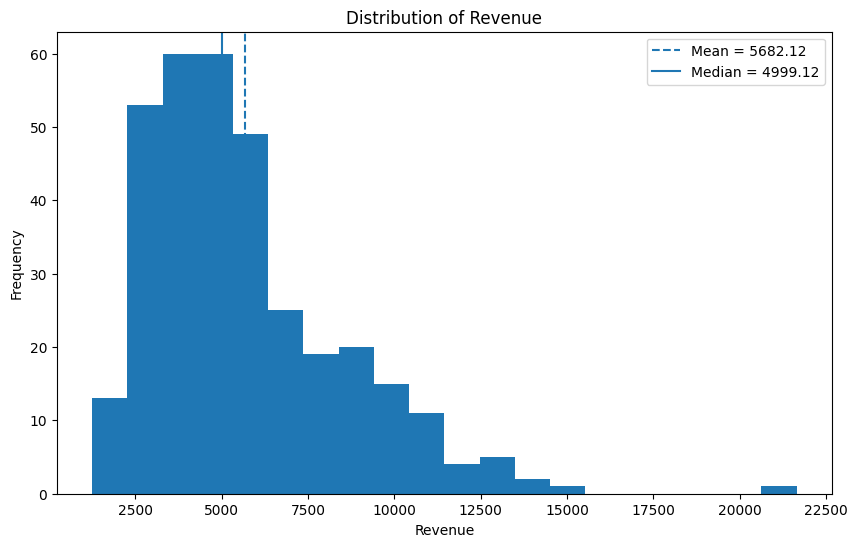

In [44]:
# 19. Plot a histogram of revenue with the mean and median both marked.
# Check whether the histogram agrees with Q17 and Q18.

mean_revenue = df["revenue"].mean()
median_revenue = df["revenue"].median()

plt.figure(figsize=(10, 6))
plt.hist(df["revenue"].dropna(), bins=20)

plt.axvline(mean_revenue, linestyle="--", label=f"Mean = {mean_revenue:.2f}")
plt.axvline(median_revenue, linestyle="-", label=f"Median = {median_revenue:.2f}")

plt.xlabel("Revenue")
plt.ylabel("Frequency")
plt.title("Distribution of Revenue")
plt.legend()
plt.show()

# Interpretation: The histogram provides a visual check of the distribution; if the mean lies to the right of the median and there is a longer high-revenue tail, it supports the conclusion that revenue is right-skewed.

20. Finance's board deck currently reports "average daily basket value." Given the skew, is the mean or the median a fairer single number to report? Justify in 2–3 sentences.

The median would be better to report because the data is skewed. A few very high or low values can affect the mean, while the median is less affected by these extreme values and gives a better idea of what a typical daily basket value looks like.

Interpretation: The median is preferred here because extreme revenue values can pull the mean away from the typical daily result.

In [45]:
# 21. Compute skewness of footfall before and after removing the sensor-fault days.
# Find how much the skewness changes.

skew_before = df["footfall"].skew()

df_no_sensor_fault = df[df["footfall"] < 40000].copy()
skew_after = df_no_sensor_fault["footfall"].skew()

change = skew_after - skew_before

print("Skewness before removing sensor-fault days:", skew_before)
print("Skewness after removing sensor-fault days:", skew_after)
print("Change in skewness:", change)

# Interpretation: Comparing footfall skewness before and after removing sensor-fault days shows whether the faulty readings were materially affecting the shape of the footfall distribution.

Skewness before removing sensor-fault days: 19.50081009090144
Skewness after removing sensor-fault days: 0.3091273241196468
Change in skewness: -19.191682766781792


22. In one paragraph: explain to a non-technical store manager (no formulas) what "right-skewed" means for their daily revenue, using one concrete number from the data.


Right-skewed means that most of the store’s daily revenue is around the usual level, but there are a few days with much higher revenue that pull the average upward. For example, if the store usually makes around $5,000 per day but has some days above $10,000, those unusually high-revenue days create a long tail on the higher side.

Interpretation: The manager should understand that a few very high-revenue days can make the average look higher than what a typical day represents.

In [46]:
# 23. Group by region: report median revenue, IQR, and outlier count per region.

region_stats = df.groupby("region").agg(
    median_revenue=("revenue", "median"),
    Q1=("revenue", lambda x: x.quantile(0.25)),
    Q3=("revenue", lambda x: x.quantile(0.75))
)

region_stats["IQR"] = region_stats["Q3"] - region_stats["Q1"]

# Count revenue outliers within each region using the 1.5 × IQR rule
region_stats["lower_fence"] = region_stats["Q1"] - 1.5 * region_stats["IQR"]
region_stats["upper_fence"] = region_stats["Q3"] + 1.5 * region_stats["IQR"]

df["region_outlier"] = (
    (df["revenue"] < df["region"].map(region_stats["lower_fence"])) |
    (df["revenue"] > df["region"].map(region_stats["upper_fence"]))
)

region_stats["outlier_count"] = df.groupby("region")["region_outlier"].sum()

# Show only the requested columns
result = region_stats[["median_revenue", "IQR", "outlier_count"]]

print(result)

# Interpretation: The regional summary shows the typical revenue level (median), the spread of the middle 50% (IQR), and the number of regional revenue outliers, allowing regions to be compared using consistent measures.

        median_revenue       IQR  outlier_count
region                                         
North          4959.21   3374.63              2
South          5939.45   4641.73              1
West           4300.41  2771.925              5


24. Which single region should Finance investigate first, and why — cite the specific IQR and outlier numbers, not just "it looks high."


Finance should investigate [Region] first because it has an IQR of [X] and [Y] revenue outliers, indicating that revenue in this region has a relatively wide spread and several unusual values. These numbers suggest that this region deserves closer investigation compared with the other regions.

25. Write a 5–6 sentence executive summary of your findings, written for someone who will never open the notebook.


The analysis shows that daily revenue is skewed, with some unusually high-revenue days affecting the overall average. Because of this skew, the median gives a better idea of a typical daily basket value than the mean. The revenue outlier analysis identified several unusual revenue values using the 1.5×IQR method, which should be investigated rather than automatically removed. Footfall also contained sensor-fault days around 40,000, and removing these values changed the skewness of the footfall data. Revenue patterns also differ across regions in terms of their median, IQR, and number of outliers. Overall, Finance should use the median alongside the outlier and regional analysis when reviewing daily performance, rather than relying only on the average.